# Credit Scoring Model — CodeAlpha ML Internship
## Predict loan default using Logistic Regression, Decision Tree, and Random Forest

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# Load dataset (going up one level from notebooks/ to reach data/)
df = pd.read_csv('../data/cs-training.csv', index_col=0)

# Basic overview
print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (150000, 11)

First 5 rows:


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [64]:
# Data types and null counts
print(df.info())
print("\nStatistics summary:")
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


Missing values per column:
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


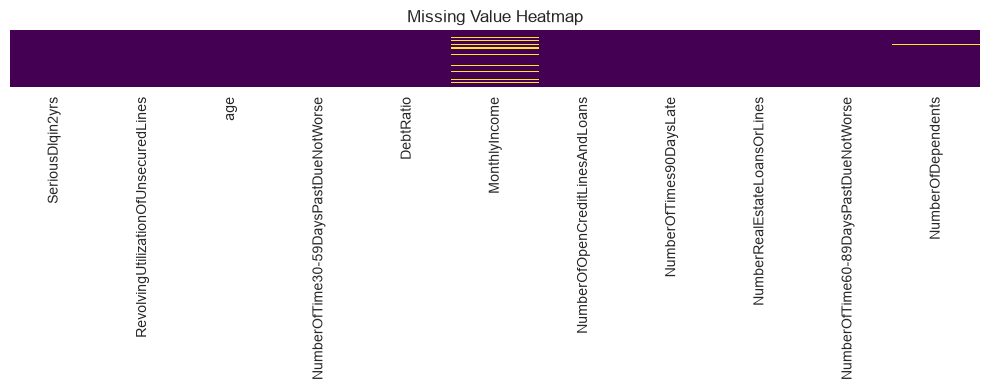

In [65]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Visualise missing values
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Value Heatmap')
plt.tight_layout()
plt.savefig('../outputs/missing_values.png', dpi=150)
plt.show()

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Default rate: 6.68%


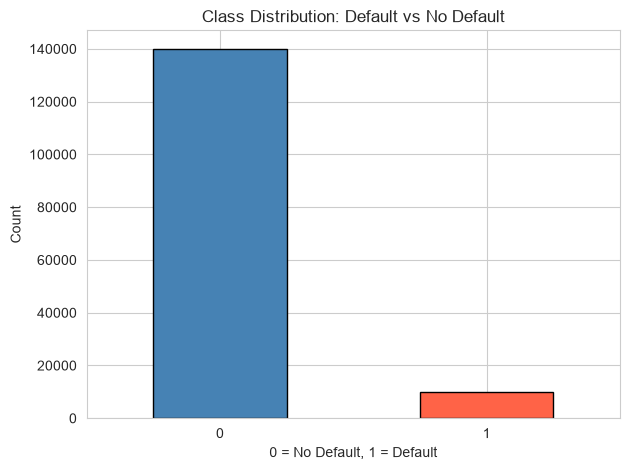

In [66]:
# Class distribution
print(df['SeriousDlqin2yrs'].value_counts())
print(f"\nDefault rate: {df['SeriousDlqin2yrs'].mean()*100:.2f}%")

df['SeriousDlqin2yrs'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'], edgecolor='black')
plt.title('Class Distribution: Default vs No Default')
plt.xlabel('0 = No Default, 1 = Default')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../outputs/class_distribution.png', dpi=150)
plt.show()

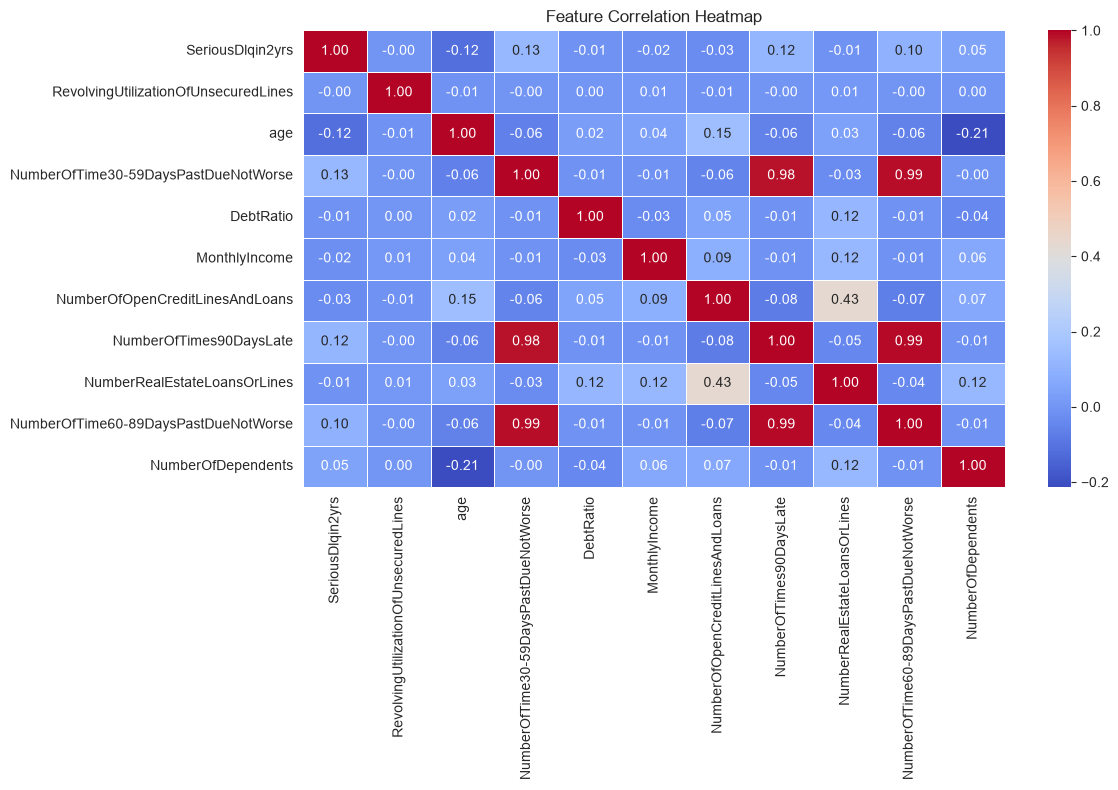

In [67]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('../outputs/correlation_heatmap.png', dpi=150)
plt.show()

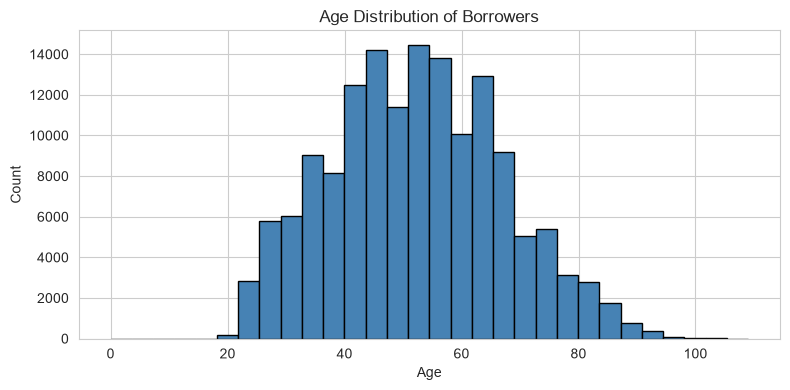

In [68]:
# Age distribution
plt.figure(figsize=(8, 4))
df['age'].hist(bins=30, color='steelblue', edgecolor='black')
plt.title('Age Distribution of Borrowers')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../outputs/age_distribution.png', dpi=150)
plt.show()

## Step 2 — Data Cleaning & Preprocessing

In [69]:
# Fill missing values with median (pandas 3.0 compatible)
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

print("Missing values after fix:")
print(df.isnull().sum())

Missing values after fix:
SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64


In [70]:
# Remove unrealistic ages
df = df[(df['age'] >= 18) & (df['age'] <= 100)]

# Cap MonthlyIncome at 99th percentile
cap = df['MonthlyIncome'].quantile(0.99)
df['MonthlyIncome'] = df['MonthlyIncome'].clip(upper=cap)

# Cap RevolvingUtilization at 1.0
df['RevolvingUtilizationOfUnsecuredLines'] = \
    df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=1.0)

print("Shape after cleaning:", df.shape)

# Separate features and target
X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']

print("Features shape:", X.shape)
print("Target distribution:\n", y.value_counts())

Shape after cleaning: (149986, 11)
Features shape: (149986, 10)
Target distribution:
 SeriousDlqin2yrs
0    139961
1     10025
Name: count, dtype: int64


## Step 3 — Feature Engineering

In [71]:
# New feature: total times ever late
df['TotalLatePayments'] = (df['NumberOfTime30-59DaysPastDueNotWorse'] +
                           df['NumberOfTime60-89DaysPastDueNotWorse'] +
                           df['NumberOfTimes90DaysLate'])

# Income per dependent
df['IncomePerDependent'] = df['MonthlyIncome'] / (df['NumberOfDependents'] + 1)

# Age groups
df['AgeGroup'] = pd.cut(df['age'],
                        bins=[18, 30, 45, 60, 100],
                        labels=['Young', 'Middle', 'Senior', 'Elderly'])
df['AgeGroup'] = df['AgeGroup'].astype('category').cat.codes

# Update X with new features
X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']

print("New feature columns:", ['TotalLatePayments', 'IncomePerDependent', 'AgeGroup'])
print("Updated X shape:", X.shape)

New feature columns: ['TotalLatePayments', 'IncomePerDependent', 'AgeGroup']
Updated X shape: (149986, 13)


## Step 4 — Train/Test Split & Handle Class Imbalance

In [72]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Feature scaling for Logistic Regression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
cols_to_scale = ['MonthlyIncome', 'DebtRatio', 
                 'RevolvingUtilizationOfUnsecuredLines', 'age']

X_scaled = X.copy()
X_scaled[cols_to_scale] = scaler.fit_transform(X[cols_to_scale])

# Split — use unscaled X for tree models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

# Split scaled version for Logistic Regression
X_train_sc, X_test_sc, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y)

print("Train size:", X_train.shape)
print("Test size: ", X_test.shape)

Train size: (119988, 13)
Test size:  (29998, 13)


In [73]:
# Apply SMOTE only on training data
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
X_train_sc_res, _ = smote.fit_resample(X_train_sc, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_res.value_counts().to_dict())

Before SMOTE: {0: 111968, 1: 8020}
After SMOTE:  {0: 111968, 1: 111968}


## Step 5 — Model Training

In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Logistic Regression (uses scaled features)
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc_res, y_train_res)
y_pred_lr = lr.predict(X_test_sc)
print("✅ Logistic Regression trained")

# 2. Decision Tree
dt = DecisionTreeClassifier(max_depth=6, min_samples_split=50, random_state=42)
dt.fit(X_train_res, y_train_res)
y_pred_dt = dt.predict(X_test)
print("✅ Decision Tree trained")

# 3. Random Forest
rf = RandomForestClassifier(
    n_estimators=100, max_depth=8, min_samples_split=50,
    class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train_res, y_train_res)
y_pred_rf = rf.predict(X_test)
print("✅ Random Forest trained")

d:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


✅ Logistic Regression trained
✅ Decision Tree trained
✅ Random Forest trained


## Step 6 — Model Evaluation


===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.97      0.81      0.88     27993
           1       0.18      0.60      0.28      2005

    accuracy                           0.80     29998
   macro avg       0.57      0.70      0.58     29998
weighted avg       0.91      0.80      0.84     29998

ROC-AUC: 0.7732


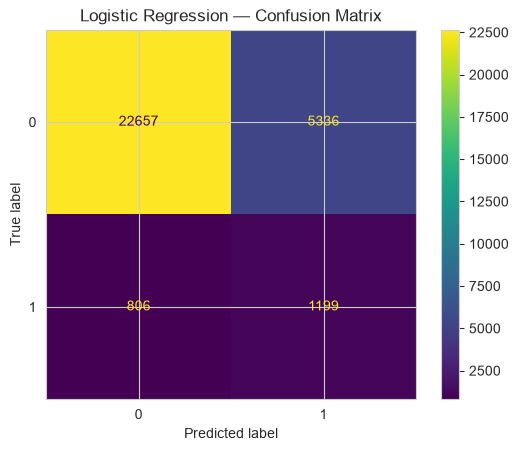


===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.98      0.79      0.88     27993
           1       0.20      0.74      0.32      2005

    accuracy                           0.79     29998
   macro avg       0.59      0.77      0.60     29998
weighted avg       0.93      0.79      0.84     29998

ROC-AUC: 0.8442


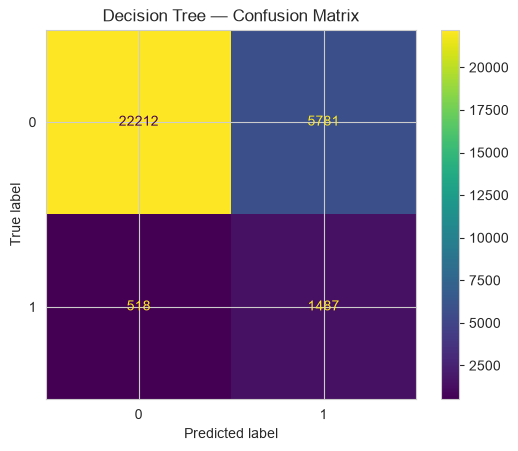


===== Random Forest =====
              precision    recall  f1-score   support

           0       0.98      0.79      0.88     27993
           1       0.21      0.75      0.32      2005

    accuracy                           0.79     29998
   macro avg       0.59      0.77      0.60     29998
weighted avg       0.93      0.79      0.84     29998

ROC-AUC: 0.8543


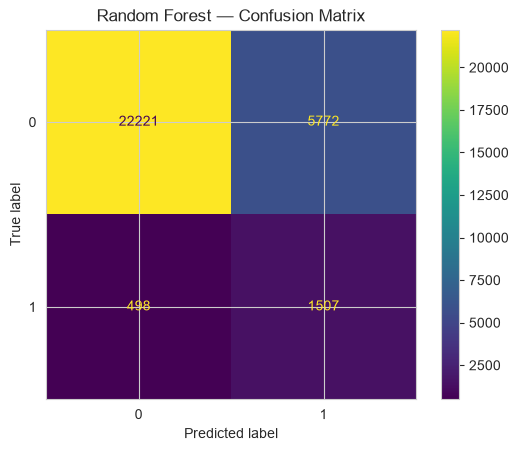

In [75]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

def evaluate_model(name, y_true, y_pred, y_prob):
    print(f'\n===== {name} =====')
    print(classification_report(y_true, y_pred))
    print(f'ROC-AUC: {roc_auc_score(y_true, y_prob):.4f}')
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm).plot()
    plt.title(f'{name} — Confusion Matrix')
    plt.savefig(f'../outputs/confusion_matrix_{name.replace(" ", "_")}.png', dpi=150)
    plt.show()

evaluate_model('Logistic Regression', y_test, y_pred_lr, lr.predict_proba(X_test_sc)[:,1])
evaluate_model('Decision Tree', y_test, y_pred_dt, dt.predict_proba(X_test)[:,1])
evaluate_model('Random Forest', y_test, y_pred_rf, rf.predict_proba(X_test)[:,1])

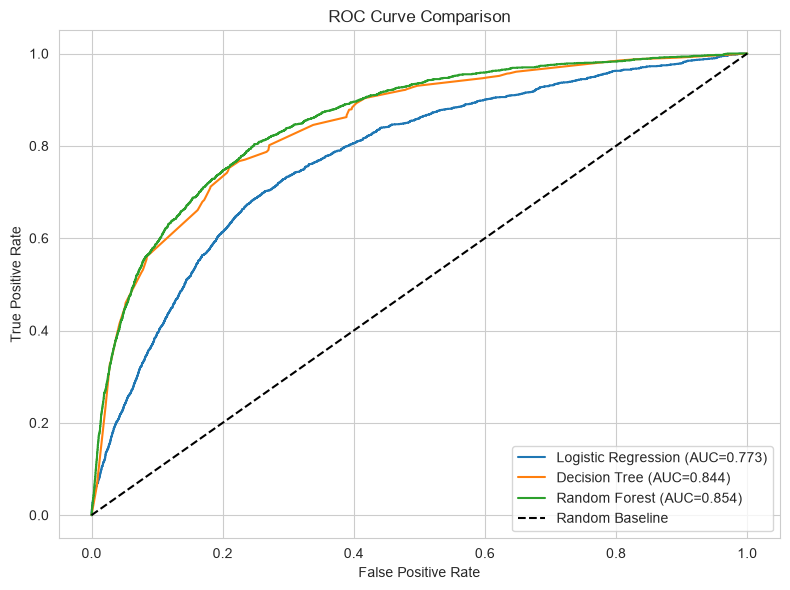

In [76]:
# ROC Curve — all 3 models on one chart
plt.figure(figsize=(8, 6))

for name, model, X_t in [
    ('Logistic Regression', lr, X_test_sc),
    ('Decision Tree', dt, X_test),
    ('Random Forest', rf, X_test)]:
    prob = model.predict_proba(X_t)[:,1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0,1],[0,1],'k--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/roc_curve.png', dpi=150)
plt.show()

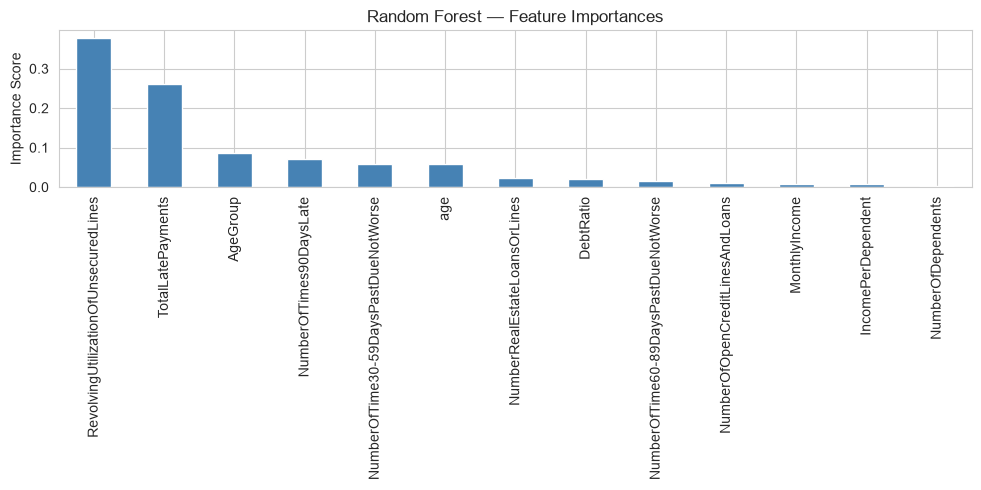

In [77]:
# Feature Importance
importances = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importances.plot(kind='bar', color='steelblue', figsize=(10, 5))
plt.title('Random Forest — Feature Importances')
plt.ylabel('Importance Score')
plt.tight_layout()
plt.savefig('../outputs/feature_importance.png', dpi=150)
plt.show()

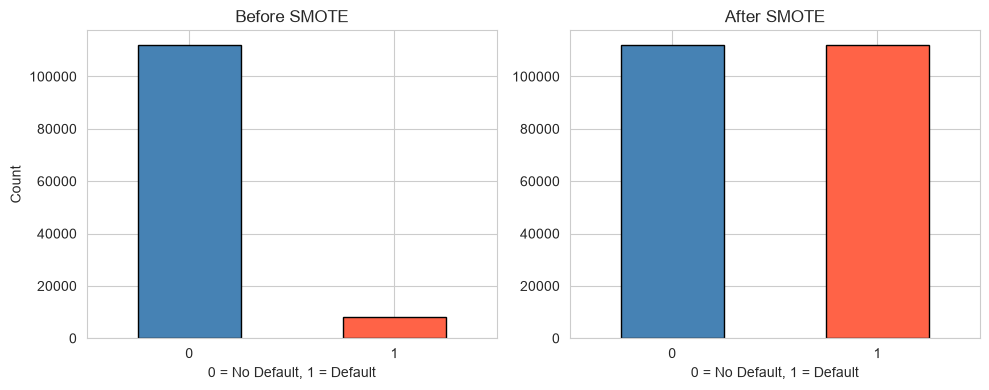

In [78]:
# SMOTE Before/After comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

y_train.value_counts().plot(kind='bar', ax=axes[0], color=['steelblue','tomato'], edgecolor='black')
axes[0].set_title('Before SMOTE')
axes[0].set_xlabel('0 = No Default, 1 = Default')
axes[0].set_ylabel('Count')
axes[0].tick_params(rotation=0)

y_train_res.value_counts().plot(kind='bar', ax=axes[1], color=['steelblue','tomato'], edgecolor='black')
axes[1].set_title('After SMOTE')
axes[1].set_xlabel('0 = No Default, 1 = Default')
axes[1].tick_params(rotation=0)

plt.tight_layout()
plt.savefig('../outputs/smote_comparison.png', dpi=150)
plt.show()

## Conclusion

The Random Forest model achieved the best performance with ROC-AUC of 0.854, outperforming Decision Tree (0.844) and Logistic Regression (0.773). The top predictors of loan default were revolving credit utilization and total late payments. SMOTE was essential in handling the 6.68% class imbalance in the dataset.

| Model | ROC-AUC | F1 (Default) | Recall (Default) |
|---|---|---|---|
| Logistic Regression | 0.773 | 0.28 | 0.60 |
| Decision Tree | 0.844 | 0.32 | 0.74 |
| Random Forest | 0.854 | 0.32 | 0.75 |